In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("simple_regression.csv")

In [3]:
data.head()

,YearsExperience,Salary
0,11.6,103198.0
1,6.6,61562.0
2,12.9,106203.0
3,10.5,102345.0
4,1.4,31606.0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  99 non-null     float64
 1   Salary           100 non-null    object 
dtypes: float64(1), object(1)
memory usage: 1.7+ KB


In [5]:
data.shape

(103, 2)

In [6]:
data.isnull().sum()

YearsExperience    4
Salary             3
dtype: int64

In [7]:
data.describe()

,YearsExperience
count,99.000000
mean,7.454545
std,5.608908
min,-2.000000
25%,3.400000
50%,6.900000
75%,10.550000
max,45.000000


### Salary column datatype change

#### find where problem of datatype

In [8]:
salary_mask = data['Salary'].str.contains(r'[$,]', na=False)
issue_rows = data.loc[salary_mask]
issue_rows

,YearsExperience,Salary
14,6.7,"₹ 64,391"
53,10.0,"₹ 82,750"
90,2.3,"₹ 30,373"


In [9]:
data['Salary'] = (
    data['Salary'].str.replace('$','',regex=False).str.replace(',','',regex=False).str.strip()
)

data['Salary'] = pd.to_numeric(data['Salary'],errors='coerce')

In [10]:
data.head()

,YearsExperience,Salary
0,11.6,103198.0
1,6.6,61562.0
2,12.9,106203.0
3,10.5,102345.0
4,1.4,31606.0


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  99 non-null     float64
 1   Salary           97 non-null     float64
dtypes: float64(2)
memory usage: 1.7 KB


In [12]:
data.describe()

,YearsExperience,Salary
count,99.000000,97.000000
mean,7.454545,74594.742268
std,5.608908,39954.553185
min,-2.000000,12000.000000
25%,3.400000,48623.000000
50%,6.900000,73200.000000
75%,10.550000,96980.000000
max,45.000000,350000.000000


### Year of experience negative value not possiable remove

In [13]:
new_data = data.loc[(data['YearsExperience'] >=0) ].reset_index(drop=True)
new_data.shape

(98, 2)

### Box plot

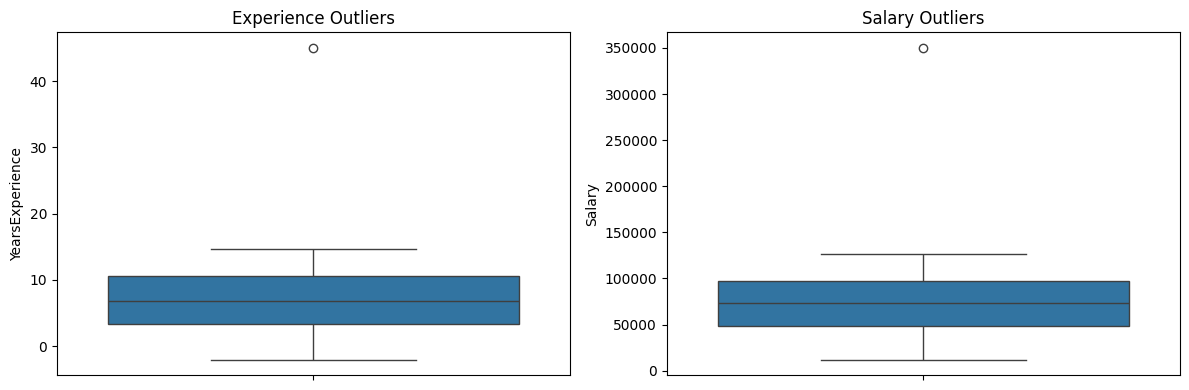

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=data, y='YearsExperience', ax=ax[0])
sns.boxplot(data=data, y='Salary', ax=ax[1])

ax[0].set_title('Experience Outliers')
ax[1].set_title('Salary Outliers')

plt.tight_layout()
plt.show()

### Outlier rows fetch

### Outlier data delete using IQR method

In [15]:
def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers

In [16]:
experience_outliers = detect_outliers(
    new_data, 'YearsExperience'
)

salary_outliers = detect_outliers(
    new_data, 'Salary'
)

print("Experience Outliers:")
print(experience_outliers)

print("Salary Outliers:")
print(salary_outliers)

Experience Outliers:
    YearsExperience    Salary
97             45.0  350000.0
Salary Outliers:
    YearsExperience    Salary
97             45.0  350000.0


In [17]:
columns = ['YearsExperience', 'Salary']

outlier_mask = pd.Series(False, index=data.index)

for column in columns:

    Q1 = new_data[column].quantile(0.25)
    Q3 = new_data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (
        (new_data[column] < lower) |
        (new_data[column] > upper)
    )

    outlier_mask |= mask

outlier_data = new_data[outlier_mask]

print(outlier_data)

    YearsExperience    Salary
97             45.0  350000.0


C:\Users\vasud\AppData\Local\Temp\ipykernel_15224\3569355575.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outlier_data = new_data[outlier_mask]


### Remove outlier

In [18]:
new_data = new_data.drop(outlier_data.index)
new_data.shape

(97, 2)

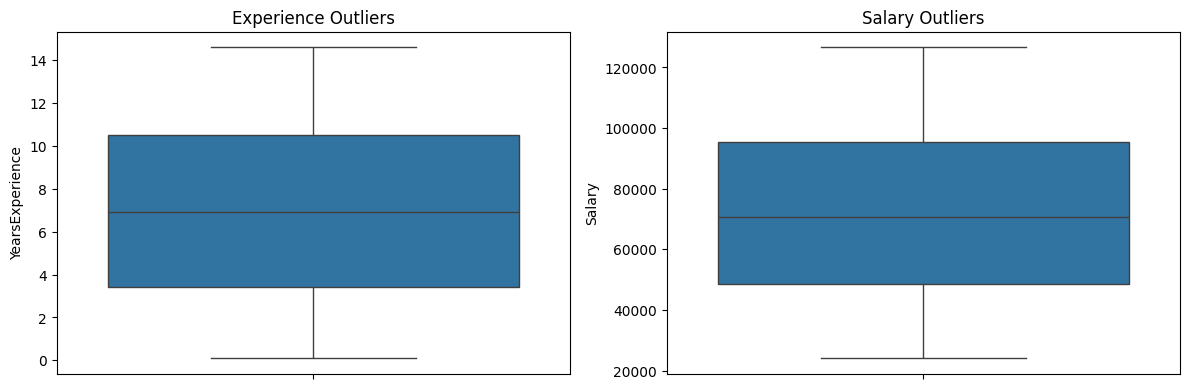

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=new_data, y='YearsExperience', ax=ax[0])
sns.boxplot(data=new_data, y='Salary', ax=ax[1])

ax[0].set_title('Experience Outliers')
ax[1].set_title('Salary Outliers')

plt.tight_layout()
plt.show()

#### Missing data fill

In [20]:
new_data.isnull().sum()

YearsExperience    0
Salary             6
dtype: int64

In [21]:
new_data['Salary'].fillna(new_data['Salary'].mean(),inplace=True)

C:\Users\vasud\AppData\Local\Temp\ipykernel_15224\3356953486.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  new_data['Salary'].fillna(new_data['Salary'].mean(),inplace=True)


In [22]:
new_data.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

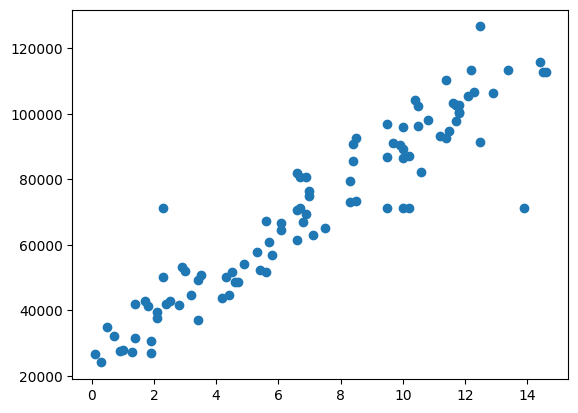

In [23]:
plt.scatter(new_data['YearsExperience'],new_data['Salary'])
plt.show()

In [44]:
new_data.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.941076
Salary,0.941076,1.000000


### Standardscaler

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
scaler = StandardScaler()
scaler

,copy,True
,with_mean,True
,with_std,True


In [26]:
scaler.fit(new_data[['Salary']])

,copy,True
,with_mean,True
,with_std,True


In [27]:
scaler_salary = scaler.transform(new_data[['Salary']])
len(scaler_salary)

97

In [28]:
from sklearn.linear_model import LinearRegression

In [29]:
model = LinearRegression()
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
X = new_data['YearsExperience'].values.reshape(-1, 1)

y = new_data['Salary'].values.reshape(-1, 1)

In [31]:
model.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [32]:
model.score(X,y)

0.8856236381836674

In [33]:
y_pred = model.predict(X)

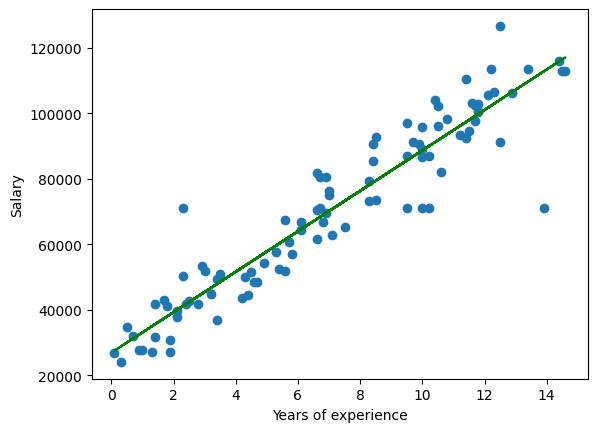

In [34]:
plt.scatter(X,y)
plt.plot(X,y_pred,color='green')

plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.show()

In [35]:
model.coef_ # Constant

array([[6174.25041786]])

In [36]:
model.intercept_ # Beta

array([26901.82500539])

In [37]:
model.positive

False

In [38]:
model.rank_

1

In [39]:
model.singular_

array([39.69736546])

In [40]:
model.n_jobs

In [41]:
from sklearn.metrics import r2_score

In [43]:
r2_score(y,y_pred)

0.8856236381836674

### Pipeline to make it

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

In [49]:
pipeline = Pipeline([
    ('model',TransformedTargetRegressor(
        regressor=LinearRegression(),
        transformer=StandardScaler()
    ))
])

In [50]:
pipeline.fit(X,y)

,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,regressor,LinearRegression()
,transformer,StandardScaler()
,func,None
,inverse_func,None
,check_inverse,True
,fit_intercept,True
,copy_X,True


In [53]:
pipeline.predict([[11.6]])

array([[98523.12985254]])

In [52]:
new_data.head()

,YearsExperience,Salary
0,11.6,103198.0
1,6.6,61562.0
2,12.9,106203.0
3,10.5,102345.0
4,1.4,31606.0
